# Workshop 3 — Segmentación de clientes con Clustering
## Equipo: Cristian Cabarcas, Samuel Herrera, Jacobo Pava y Alexander Vargas
### K-Means vs. Agglomerative vs. DBSCAN → Clasificador supervisado

**Dataset:** Mall Customer Segmentation Data (200 clientes).

Flujo: preprocesamiento → tres métodos de clustering → visualización PCA 3D → comparación → selección de las clases naturales → perfilado → clasificador que predice el segmento.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")

## Fase 0 — Carga y preprocesamiento
### 2.1 Exploración inicial

In [ ]:
from google.colab import drive
import pandas as pd
import os

# 1. Conectar Google Drive
drive.mount('/content/drive')

# 2. Definir la ruta del dataset en Google Drive
ruta = '/content/drive/MyDrive/FAA IA/data/Mall_Customers.csv'

# 3. Cargar el dataset
df = pd.read_csv(ruta)

# 4. En esta versión del CSV la columna se llama "Gender"; la renombramos a "Genre" como en el enunciado.
df = df.rename(columns={"Gender": "Genre"})

# 5. Mostrar información del dataset
print("Shape:", df.shape)
display(df.head())

Mounted at /content/drive
Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nTipos de datos:")
print(df.dtypes)

Valores nulos por columna:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0

Tipos de datos:
CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


**Exploración adicional:** estadísticos descriptivos, conteo por género, distribuciones, relaciones entre variables y correlaciones.

In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Genre
Female    112
Male       88
Name: count, dtype: int64


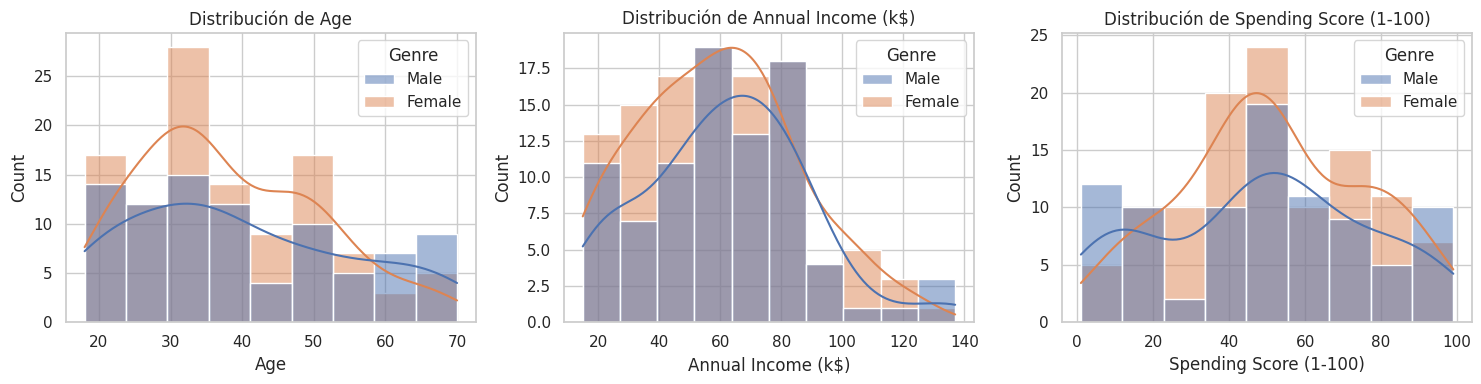

In [ ]:
print(df["Genre"].value_counts())

num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Genre", kde=True, ax=ax)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout(); plt.show()

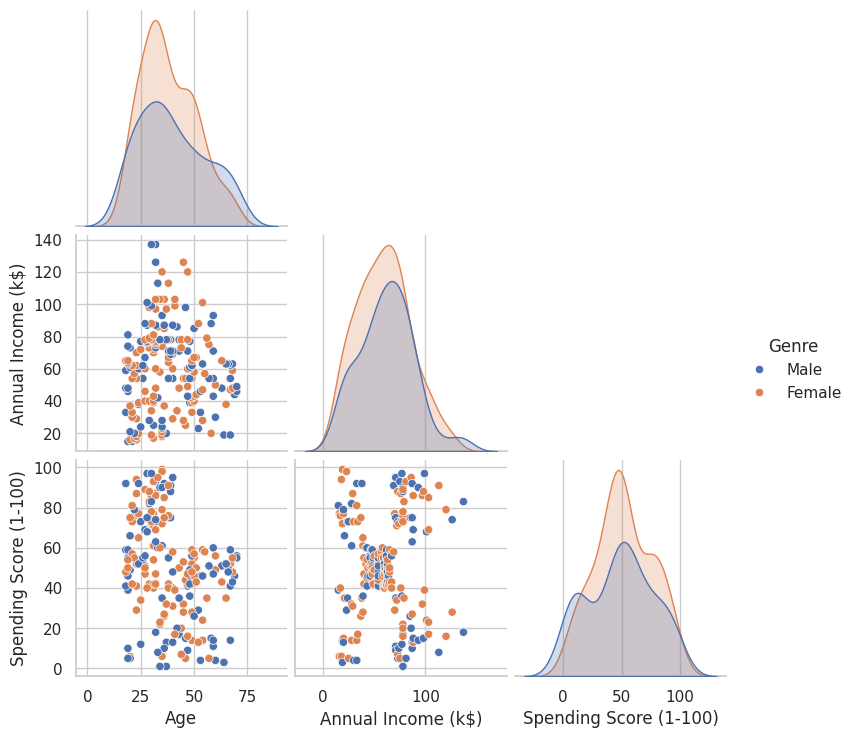

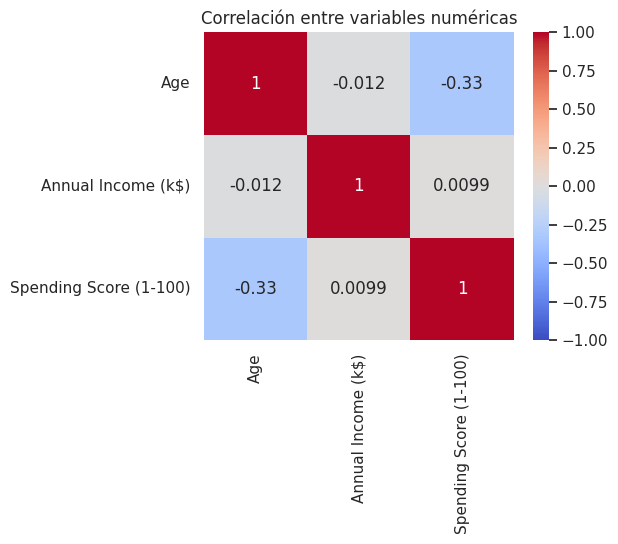

In [ ]:
sns.pairplot(df[num_cols + ["Genre"]], hue="Genre", corner=True)
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

### Respuestas — Exploración

- **¿Hay valores nulos?** No. Ninguna columna tiene nulos y tampoco hay filas duplicadas.
- **Tipos de dato:** `CustomerID`, `Age`, `Annual Income (k$)` y `Spending Score (1-100)` son **numéricas enteras**; `Genre` es la única **categórica** (Female = 112, Male = 88).
- **Otras observaciones:**
  - Las edades van de 18 a 70 años (media ≈ 39), el ingreso de 15k a 137k (media ≈ 61k) y el Spending Score de 1 a 99 (media ≈ 50).
  - Las correlaciones lineales son débiles. La más notable es negativa entre **edad y gasto** (−0.33): los clientes mayores tienden a gastar menos.
  - En el gráfico ingreso vs. gasto del pairplot se intuyen cinco nubes de puntos (una central y cuatro en las esquinas), una primera pista de que hay grupos.
  - Las distribuciones de hombres y mujeres son muy parecidas en las tres variables numéricas.
- **Nota:** en el CSV entregado la columna se llama `Gender`, no `Genre`; la renombramos para usar los nombres del enunciado.

### 2.2 Selección de variables y 2.3 Codificación de `Genre`

In [ ]:
df = df.drop(columns=["CustomerID"])

# Genre tiene solo 2 categorías y no tiene orden natural -> mapeo manual a 0/1
# (equivale a OneHotEncoder con drop="first"; con 2 categorías no se introduce un orden falso).
df["Genre_encoded"] = df["Genre"].map({"Female": 0, "Male": 1})
df[["Genre", "Genre_encoded"]].value_counts()

,,count
Genre,Genre_encoded,
Female,0,112
Male,1,88


### 2.4 Estandarización

In [ ]:
features = ["Genre_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

pd.DataFrame(X_scaled, columns=features).describe().loc[["mean", "std", "min", "max"]].round(2)

,Genre_encoded,Age,Annual Income (k$),Spending Score (1-100)
mean,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.89,-1.50,-1.74,-1.91
max,1.13,2.24,2.92,1.89


### Respuesta — ¿Por qué estandarizar?

K-Means, Agglomerative (Ward) y DBSCAN se basan en **distancias euclidianas**. Sin estandarizar, cada variable pesa según su escala: `Annual Income` tiene un rango de ≈ 122 (15 a 137) y `Age` de ≈ 52 (18 a 70), mientras que `Genre_encoded` solo vale 0 o 1. El ingreso y el gasto dominarían la distancia y el género casi no influiría, así que los clusters reflejarían las **unidades de medida** y no la información de cada variable. Además, el `eps` de DBSCAN no significaría lo mismo en cada dimensión. Tras `StandardScaler`, todas las variables tienen media 0 y desviación 1 y contribuyen por igual (ver la tabla de arriba).

**Función auxiliar de perfilado.** Para comparar soluciones de clustering usamos un resumen por cluster: tamaño, media de cada variable original y porcentaje de hombres. Es una versión compacta de lo que pide la Fase 7, y la usamos desde ahora para respaldar con datos la elección de cada configuración.

In [ ]:
def perfil_rapido(labels):
    g = df.assign(Cluster=labels).groupby("Cluster")
    t = g[num_cols].mean().round(1)
    t["n"] = g.size()
    t["% hombres"] = (g["Genre_encoded"].mean() * 100).round(0)
    return t

## Fase 1 — K-Means
### 3.1 Método del codo y 3.2 Silhouette Score para cada k

In [ ]:
ks = range(2, 9)
rows = []
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    rows.append({"k": k, "Inercia": model.inertia_, "Silhouette": silhouette_score(X_scaled, labels)})

km_table = pd.DataFrame(rows).set_index("k")
km_table["% reducción de inercia"] = -km_table["Inercia"].pct_change() * 100
km_table.round(3)

,Inercia,Silhouette,% reducción de inercia
k,,,
2,588.803,0.252,NaN
3,476.788,0.260,19.024
4,388.718,0.298,18.471
5,331.310,0.304,14.769
6,276.412,0.331,16.570
7,236.205,0.357,14.546
8,199.750,0.388,15.433


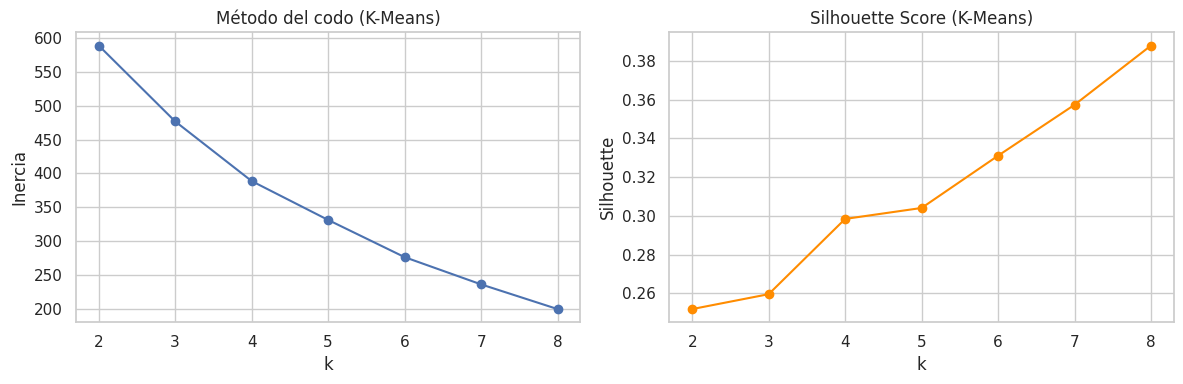

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_table.index, km_table["Inercia"], "o-")
axes[0].set(title="Método del codo (K-Means)", xlabel="k", ylabel="Inercia")
axes[1].plot(km_table.index, km_table["Silhouette"], "o-", color="darkorange")
axes[1].set(title="Silhouette Score (K-Means)", xlabel="k", ylabel="Silhouette")
plt.tight_layout(); plt.show()

Como el codo no es claro y el Silhouette sigue subiendo, comparamos **qué segmentos produce** cada candidato (k = 5, 6 y 8): ¿un k mayor descubre comportamientos nuevos o solo divide grupos existentes por género?

In [ ]:
for k in [5, 6, 8]:
    print(f"--- K-Means k={k} ---")
    print(perfil_rapido(KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)), "\n")

--- K-Means k=5 ---
          Age  Annual Income (k$)  Spending Score (1-100)   n  % hombres
Cluster                                                                 
0        32.7                86.5                    82.1  39       46.0
1        36.5                89.5                    18.0  29       45.0
2        49.8                49.2                    40.1  43        0.0
3        24.9                39.7                    61.2  54       41.0
4        55.7                53.7                    36.8  35      100.0 

--- K-Means k=6 ---
          Age  Annual Income (k$)  Spending Score (1-100)   n  % hombres
Cluster                                                                 
0        50.6                49.7                    40.1  41        0.0
1        28.1                58.3                    71.3  38      100.0
2        26.0                39.5                    59.5  34        0.0
3        55.6                52.8                    36.2  35      100.0
4        

### Respuestas — K-Means

| k | Inercia | Silhouette |
|---:|---:|---:|
| 2 | 588.80 | 0.252 |
| 3 | 476.79 | 0.260 |
| 4 | 388.72 | 0.298 |
| 5 | 331.31 | 0.304 |
| 6 | 276.41 | 0.331 |
| 7 | 236.21 | 0.357 |
| 8 | 199.75 | 0.388 |

**1. ¿El codo coincide con el k de mayor Silhouette?** No, y de hecho **no hay un codo claro**. La inercia baja de forma pareja: cada cluster adicional la reduce entre 15% y 19%, sin un punto donde la mejora caiga de golpe. El método del codo, por sí solo, no permite elegir k. El Silhouette, en cambio, **sigue subiendo hasta k = 8** (0.388), el máximo del rango.

**2. ¿Qué k seleccionamos? → k = 6.** Como el codo no es concluyente, la decisión se apoya en los perfiles de arriba, el dendrograma (Fase 2) y la interpretabilidad:

- **k = 8 solo divide por género.** Sus 8 clusters son 4 comportamientos repetidos en hombres y mujeres. Por ejemplo, el par de ingreso y gasto altos tiene medias de 87.1k / 82.7 (hombres) y 85.3k / 80.6 (mujeres), y el par de ingreso alto y gasto bajo, 85.9k / 14.2 y 87.9k / 24.6. Todos los clusters son 0% o 100% hombres. El Silhouette sube porque `Genre_encoded`, al ser binaria, pone a hombres y mujeres en dos planos separados, no porque aparezcan segmentos nuevos.
- **k = 5 ya separa los comportamientos principales** (ingreso alto con gasto alto, ingreso alto con gasto bajo, jóvenes, maduros). Pero su grupo joven de 54 clientes es mixto en género, y los maduros quedan divididos en mujeres y hombres.
- **k = 6** tiene mejor Silhouette que k = 5 (0.331 vs. 0.304) y coincide con el corte más claro del dendrograma. Por eso es la opción elegida.

**Compromiso que aceptamos:** con k = 6 el grupo joven se divide por género, y como efecto secundario los hombres jóvenes de ingreso alto y gasto alto pasan al cluster de hombres jóvenes. Así, el cluster premium queda casi solo con mujeres (9% hombres). Lo tenemos en cuenta al interpretar los segmentos en la Fase 7.

In [ ]:
labels_kmeans = KMeans(n_clusters=6, random_state=42, n_init=10).fit_predict(X_scaled)
print("Silhouette K-Means (k=6):", round(silhouette_score(X_scaled, labels_kmeans), 4))

Silhouette K-Means (k=6): 0.3311


## Fase 2 — Clustering jerárquico aglomerativo (Ward)

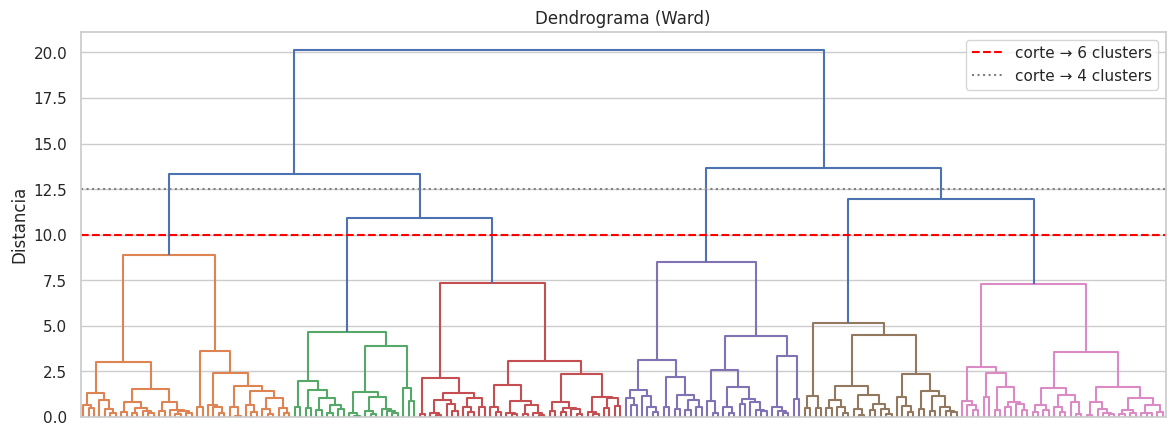

,n_clusters tras el corte,distancia de fusión,salto hasta la siguiente fusión
0,2,20.12,6.48
1,3,13.64,0.33
2,4,13.31,1.35
3,5,11.96,1.03
4,6,10.93,2.05
5,7,8.88,0.37
6,8,8.51,1.14
7,9,7.37,0.09
8,10,7.28,NaN


In [ ]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=10)
plt.axhline(10, color="red", ls="--", label="corte → 6 clusters")
plt.axhline(12.5, color="gray", ls=":", label="corte → 4 clusters")
plt.title("Dendrograma (Ward)"); plt.ylabel("Distancia")
plt.legend(); plt.show()

# Distancias de las últimas fusiones: un salto grande entre dos fusiones consecutivas indica un buen lugar para cortar
fusiones = pd.DataFrame({"n_clusters tras el corte": range(2, 11),
                         "distancia de fusión": Z[-9:, 2][::-1].round(2)})
fusiones["salto hasta la siguiente fusión"] = (fusiones["distancia de fusión"]
                                               - fusiones["distancia de fusión"].shift(-1)).round(2)
fusiones

In [ ]:
rows = []
for k in ks:
    l = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    rows.append({"k": k, "Silhouette": silhouette_score(X_scaled, l)})
ag_table = pd.DataFrame(rows).set_index("k")
ag_table.round(3)

,Silhouette
k,
2,0.242
3,0.248
4,0.263
5,0.287
6,0.310
7,0.346
8,0.379


In [ ]:
labels_agglomerative = AgglomerativeClustering(n_clusters=6, linkage="ward").fit_predict(X_scaled)
from sklearn.metrics import adjusted_rand_score

print("Silhouette Agglomerative (k=6):", round(silhouette_score(X_scaled, labels_agglomerative), 4))
# Índice de Rand ajustado: qué tanto coinciden las particiones de K-Means y Agglomerative (1 = idénticas, ~0 = al azar)
print("Índice de Rand ajustado vs. K-Means:", round(adjusted_rand_score(labels_kmeans, labels_agglomerative), 3))
perfil_rapido(labels_agglomerative)

Silhouette Agglomerative (k=6): 0.3102
Índice de Rand ajustado vs. K-Means: 0.652


,Age,Annual Income (k$),Spending Score (1-100),n,% hombres
Cluster,,,,,
0,32.7,86.5,82.1,39,46.0
1,27.1,46.5,58.6,38,0.0
2,41.5,89.1,16.2,33,55.0
3,49.8,44.1,39.7,38,0.0
4,56.6,50.0,41.3,29,100.0
5,24.6,39.2,59.7,23,100.0


### Respuestas — Agglomerative

| k | Silhouette (Ward) |
|---:|---:|
| 2 | 0.242 |
| 3 | 0.248 |
| 4 | 0.263 |
| 5 | 0.287 |
| 6 | 0.310 |
| 7 | 0.346 |
| 8 | 0.379 |

- **¿Cuántos grupos sugiere el dendrograma?** La fusión más alta (≈ 20.1) separa **2** grandes grupos, con un salto muy grande respecto a la siguiente fusión (≈ 6.5). Después de ese primer corte, el mayor salto entre fusiones consecutivas (≈ 2.05, de 10.93 a 8.88) aparece al cortar en **6 clusters** (línea roja). Ese es el corte natural más claro después del primero. Cortar en 4 (línea gris) también es posible, pero con un margen menor (≈ 1.35).
- **¿Coincide con el mejor k por Silhouette?** No. El Silhouette vuelve a ser máximo en k = 8 (0.379), por el mismo efecto de dividir por género que vimos en K-Means. Seguimos el dendrograma y usamos **k = 6** (Silhouette 0.310).
- **Perfil de la solución k = 6:** los segmentos son muy parecidos a los de K-Means, aunque no idénticos: el índice de Rand ajustado entre ambas particiones es **0.65** (1 = particiones idénticas, ≈ 0 = coincidencia al azar). Hay una diferencia importante. Tiene un grupo de ingreso y gasto altos (39 clientes), uno de ingreso alto y gasto bajo (33) y cuatro grupos de jóvenes y maduros divididos por género. La diferencia es que aquí el grupo premium es **mixto en género** (46% hombres), mientras que en K-Means quedó casi solo con mujeres.

## Fase 3 — DBSCAN

In [ ]:
rows = []
for eps in [0.3, 0.5, 0.7, 0.9, 1.1]:
    for ms in [3, 5, 8, 10]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(l)) - (1 if -1 in l else 0)
        n_noise = int((l == -1).sum())
        mask = l != -1
        s = silhouette_score(X_scaled[mask], l[mask]) if n_cl > 1 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_cl, "ruido": n_noise,
                     "% ruido": n_noise / len(l) * 100, "Silhouette (sin ruido)": s})
db_table = pd.DataFrame(rows)
db_table.round(3)

,eps,min_samples,clusters,ruido,% ruido,Silhouette (sin ruido)
0,0.3,3,14,144,72.0,0.629
1,0.3,5,1,194,97.0,NaN
2,0.3,8,0,200,100.0,NaN
3,0.3,10,0,200,100.0,NaN
4,0.5,3,18,49,24.5,0.475
5,0.5,5,9,105,52.5,0.540
6,0.5,8,2,169,84.5,0.709
7,0.5,10,2,178,89.0,0.769
8,0.7,3,9,14,7.0,0.132
9,0.7,5,7,37,18.5,0.277


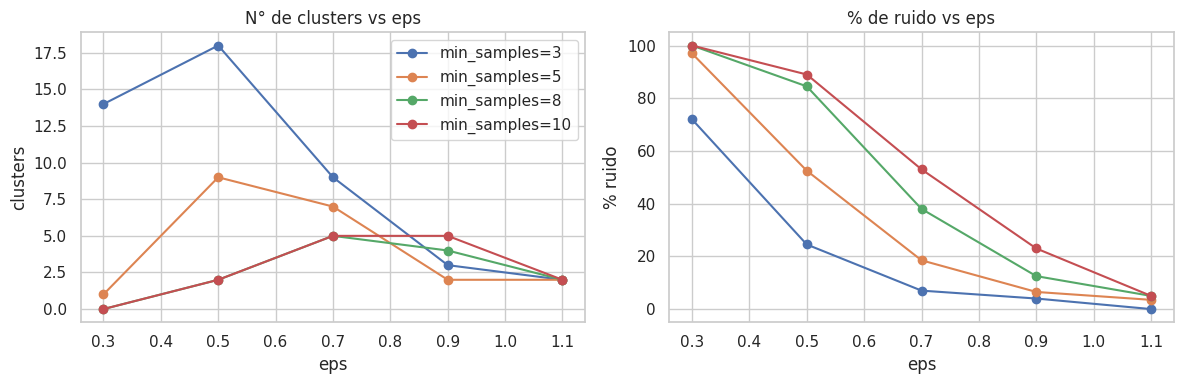

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ms, g in db_table.groupby("min_samples"):
    axes[0].plot(g["eps"], g["clusters"], "o-", label=f"min_samples={ms}")
    axes[1].plot(g["eps"], g["% ruido"], "o-", label=f"min_samples={ms}")
axes[0].set(title="N° de clusters vs eps", xlabel="eps", ylabel="clusters")
axes[1].set(title="% de ruido vs eps", xlabel="eps", ylabel="% ruido")
axes[0].legend(); plt.tight_layout(); plt.show()

In [ ]:
labels_dbscan = DBSCAN(eps=0.9, min_samples=8).fit_predict(X_scaled)
mask = labels_dbscan != -1

print("Clusters:", len(set(labels_dbscan)) - 1)
print("Puntos de ruido:", (~mask).sum())
print("Silhouette (sin ruido):", round(silhouette_score(X_scaled[mask], labels_dbscan[mask]), 4))

# Perfil de cada cluster de DBSCAN; la fila -1 es el ruido
perfil_rapido(labels_dbscan)

Clusters: 4
Puntos de ruido: 25
Silhouette (sin ruido): 0.2685


,Age,Annual Income (k$),Spending Score (1-100),n,% hombres
Cluster,,,,,
-1,42.2,67.7,19.4,25,64.0
0,37.3,57.7,54.8,103,0.0
1,25.8,27.4,75.9,10,100.0
2,51.7,64.8,36.1,36,100.0
3,29.0,72.1,71.4,26,100.0


### Respuestas — DBSCAN

Elegimos **eps = 0.9, min_samples = 8**: da 4 clusters con 12.5% de ruido, sin un solo cluster gigante ni casi todo marcado como ruido.

**1. ¿Cuántos clusters?** 4.

**2. ¿Cuántos puntos de ruido?** 25 (12.5% de los clientes). Silhouette sin ruido = 0.269.

**Configuraciones descartadas:**
- Con eps = 0.3–0.5 casi todas las combinaciones dejan entre 50% y 100% de ruido. La excepción (eps = 0.5, min_samples = 3) genera 18 micro-clusters. Sus Silhouette altos se calculan sobre muy pocos puntos y no son comparables.
- Con eps = 0.7 sale demasiado ruido, o muchos clusters pequeños.
- Con eps = 1.1 todo colapsa en **2 clusters**, que son simplemente hombres y mujeres.

**3. Efecto de los parámetros** (ver los gráficos de clusters y ruido vs. eps):
- **Al aumentar `eps`**, los vecindarios son más grandes, las regiones densas se unen y el ruido baja (por ejemplo, con min_samples = 8 pasa de 100% a 5%). El número de clusters primero sube, al salir grupos del ruido, y luego baja a 2, al fusionarse.
- **Al aumentar `min_samples`**, se exige más densidad para formar un cluster: el ruido aumenta y los grupos pequeños desaparecen. Por ejemplo, con eps = 0.9 el ruido pasa de 8 puntos (min_samples = 3) a 46 (min_samples = 10).

**Perfil de los clusters de DBSCAN:**

| Cluster | n | % hombres | Edad | Ingreso | Gasto | Lectura |
|---:|---:|---:|---:|---:|---:|---|
| 0 | 103 | 0% | 37.3 | 57.7 | 54.8 | **Todas las mujeres en un solo grupo**, sin distinguir perfiles |
| 1 | 10 | 100% | 25.8 | 27.4 | 75.9 | Hombres jóvenes de ingreso bajo y gasto alto |
| 2 | 36 | 100% | 51.7 | 64.8 | 36.1 | Hombres maduros de gasto moderado-bajo |
| 3 | 26 | 100% | 29.0 | 72.1 | 71.4 | Hombres jóvenes de ingreso medio-alto y gasto alto |
| −1 (ruido) | 25 | 64% | 42.2 | 67.7 | **19.4** | Sobre todo clientes de **gasto bajo** e ingreso medio-alto |

DBSCAN separa bien a los hombres, pero junta a las 103 mujeres en un solo cluster: la densidad dentro de la "tira" femenina es continua y no encuentra cortes. Además, el ruido no es aleatorio: concentra a clientes de gasto bajo e ingreso medio-alto, un grupo de baja densidad que los otros métodos sí identifican como segmento (ingreso alto, gasto bajo). Para el negocio, perder justamente ese grupo como "ruido" es una desventaja importante.

## Fase 4 — Visualización con PCA en 3D

In [ ]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_.round(4))
print("Varianza explicada acumulada:", round(pca.explained_variance_ratio_.sum(), 4))

# Cargas: cuánto aporta cada variable a cada componente
pd.DataFrame(pca.components_, columns=features, index=["PC1", "PC2", "PC3"]).round(3)

Varianza explicada por cada componente: [0.3369 0.2623 0.2326]
Varianza explicada acumulada: 0.8318


,Genre_encoded,Age,Annual Income (k$),Spending Score (1-100)
PC1,0.234,0.688,-0.006,-0.687
PC2,0.627,-0.104,0.765,0.103
PC3,0.743,-0.122,-0.644,0.137


### Respuesta — Varianza explicada

Las 3 componentes capturan **≈ 83.2%** de la varianza total (33.7% + 26.2% + 23.3%). Es suficiente para confiar en la visualización a grandes rasgos, pero se pierde ≈ 17% de la información: dos clusters que se vean superpuestos en 3D podrían estar separados en el espacio original de 4 dimensiones.

Las cargas ayudan a leer los ejes:
- **PC1** contrapone edad y gasto (0.69 y −0.69): valores altos indican clientes mayores que gastan poco.
- **PC2** está dominada por el ingreso (0.77) y el género (0.63).
- **PC3** contrapone género (0.74) e ingreso (−0.64).

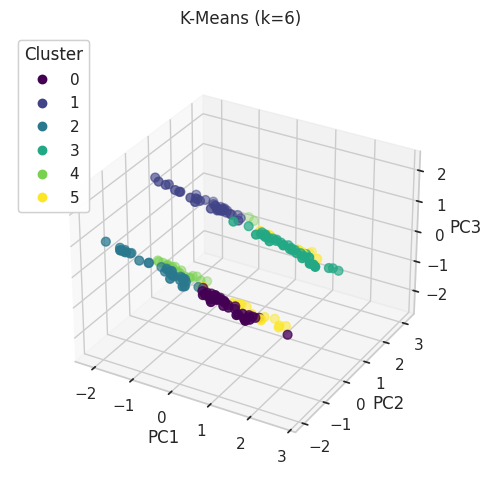

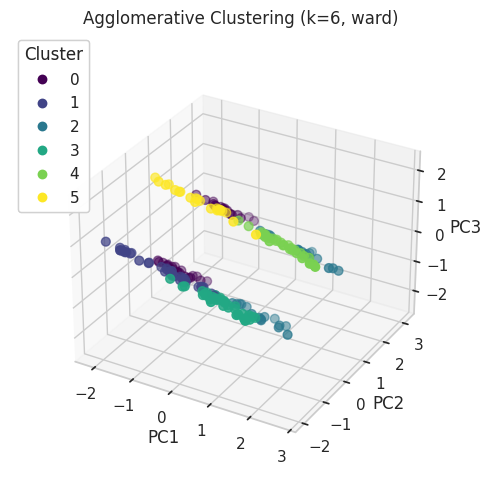

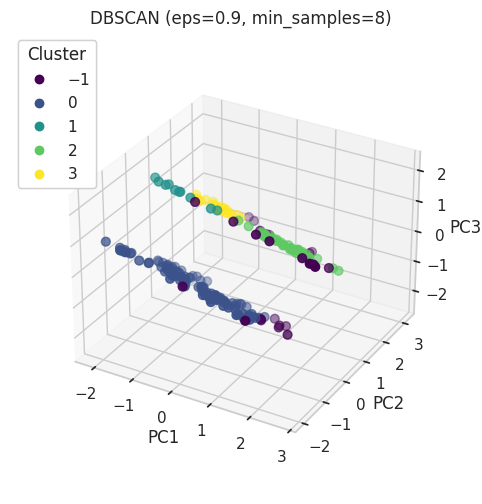

In [ ]:
def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_box_aspect(None, zoom=0.85)  # reduce un poco el cubo para que el título del eje PC3 no quede cortado

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title)

    legend = ax.legend(*scatter.legend_elements(), title="Cluster", loc="upper left")  # a la izquierda para no tapar el eje PC3
    ax.add_artist(legend)

    plt.show()

plot_clusters_3d(X_pca, labels_kmeans, "K-Means (k=6)")
plot_clusters_3d(X_pca, labels_agglomerative, "Agglomerative Clustering (k=6, ward)")
plot_clusters_3d(X_pca, labels_dbscan, "DBSCAN (eps=0.9, min_samples=8)")

Versión alternativa de DBSCAN con el ruido en gris, para que no se confunda con un cluster más:

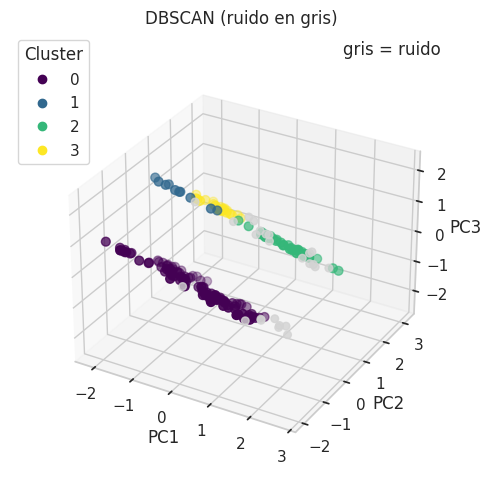

In [ ]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.set_box_aspect(None, zoom=0.85)
noise = labels_dbscan == -1
ax.scatter(*X_pca[noise].T, c="lightgray", s=30, alpha=0.8)
sc = ax.scatter(*X_pca[~noise].T, c=labels_dbscan[~noise], cmap="viridis", s=40)
ax.legend(*sc.legend_elements(), title="Cluster", loc="upper left")
ax.text2D(0.72, 0.95, "gris = ruido", transform=ax.transAxes)
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="DBSCAN (ruido en gris)")
plt.show()

### Observaciones de los gráficos 3D

- En los tres gráficos los puntos forman **dos "tiras" paralelas**, que corresponden a los dos valores de `Genre_encoded`. Por eso el género pesa tanto en todos los métodos.
- Las tiras son **casi lineales**, y los clusters no aparecen como nubes separadas: **forman tramos continuos de cada tira, con solapamiento en las fronteras** entre tramos vecinos. Es decir, la separación entre segmentos es gradual, no nítida.
- **K-Means y Agglomerative** dividen las tiras en tramos muy parecidos. Los clusters mixtos en género (el 5 en K-Means y el premium en Agglomerative) aparecen en ambas tiras.
- **DBSCAN:** su cluster 0 ocupa una tira completa (las 103 mujeres), mientras que la otra tira sí se divide en 3 grupos. Con el esqueleto original, el ruido (−1) recibe el color más oscuro de la escala `viridis` y **parece un cluster más**, lo que dificulta la lectura. En la versión con el ruido en gris se ve que esos puntos se concentran hacia los extremos de las tiras y en las zonas de transición, y no forman un grupo propio.

## Fase 5 — Comparación final con Silhouette Score

In [ ]:
comparacion = pd.DataFrame({
    "Método": ["K-Means", "Agglomerative", "DBSCAN"],
    "Parámetros": ["k = 6", 'k = 6, linkage="ward"', "eps = 0.9, min_samples = 8"],
    "N° de clusters": [6, 6, len(set(labels_dbscan)) - 1],
    "N° de puntos de ruido": ["N/A", "N/A", int((labels_dbscan == -1).sum())],
    "Silhouette Score": [
        silhouette_score(X_scaled, labels_kmeans),
        silhouette_score(X_scaled, labels_agglomerative),
        silhouette_score(X_scaled[mask], labels_dbscan[mask]),
    ],
}).set_index("Método")
comparacion.round(3)

,Parámetros,N° de clusters,N° de puntos de ruido,Silhouette Score
Método,,,,
K-Means,k = 6,6,N/A,0.331
Agglomerative,"k = 6, linkage=""ward""",6,N/A,0.310
DBSCAN,"eps = 0.9, min_samples = 8",4,25,0.269


In [ ]:
# Referencia: mejor Silhouette alcanzable por cada método en el rango explorado
print("Mejor K-Means:       k =", km_table["Silhouette"].idxmax(), "->", round(km_table["Silhouette"].max(), 3))
print("Mejor Agglomerative: k =", ag_table["Silhouette"].idxmax(), "->", round(ag_table["Silhouette"].max(), 3))
print("\nMejores DBSCAN con como máximo 25% de ruido:")
razonables = db_table[(db_table["% ruido"] <= 25) & (db_table["clusters"] >= 2)]
print(razonables.sort_values("Silhouette (sin ruido)", ascending=False).head(3).round(3).to_string(index=False))

Mejor K-Means:       k = 8 -> 0.388
Mejor Agglomerative: k = 8 -> 0.379

Mejores DBSCAN con como máximo 25% de ruido:
 eps  min_samples  clusters  ruido  % ruido  Silhouette (sin ruido)
 0.5            3        18     49     24.5                   0.475
 0.9           10         5     46     23.0                   0.307
 0.9            5         2     13      6.5                   0.292


### Tabla comparativa

| Método | Parámetros | N° de clusters | N° de puntos de ruido | Silhouette Score |
|---|---|---:|---:|---:|
| K-Means | `k = 6` | 6 | N/A | **0.331** |
| Agglomerative | `k = 6, linkage="ward"` | 6 | N/A | 0.310 |
| DBSCAN | `eps = 0.9, min_samples = 8` | 4 | 25 | 0.269 |

*Referencia:* con k = 8, K-Means llega a 0.388 y Agglomerative a 0.379, pero esas soluciones solo dividen los grupos por género (Fase 1). En DBSCAN, `eps = 0.5, min_samples = 3` tiene un Silhouette más alto (0.475), pero genera 18 micro-clusters y deja el 24.5% de los clientes como ruido.

## Fase 6 — ¿Cuáles son las clases naturales?

### Respuesta — Clases naturales

**Consideramos que existen 6 grupos naturales y los definimos con K-Means (k = 6).**

1. **Silhouette:** entre las soluciones interpretables, K-Means con k = 6 tiene el mejor valor (0.331), por encima de Agglomerative con k = 6 (0.310) y DBSCAN (0.269).
2. **Coherencia entre métodos:** el dendrograma sugiere 6 grupos de forma independiente, y Agglomerative con k = 6 recupera segmentos muy parecidos (índice de Rand ajustado = 0.65), con una diferencia importante: su grupo premium es mixto en género. Que dos algoritmos distintos coincidan en buena medida indica que la estructura principal no depende del método elegido.
3. **Sin ruido:** a cada cliente se le asigna un segmento, lo cual es necesario para el negocio y para entrenar el clasificador. DBSCAN deja como ruido a 25 clientes, en su mayoría de gasto bajo e ingreso medio-alto, un grupo comercialmente importante, y junta a todas las mujeres en un solo grupo.
4. **Interpretabilidad:** cada cluster de k = 6 tiene un perfil distinto (Fase 7). Las soluciones con k = 7–8 tienen mayor Silhouette solo porque dividen por género.
5. **Forma de los grupos:** en el PCA 3D los clusters forman tramos continuos con solapamiento en las fronteras, no nubes claramente separadas. Esto no favorece a DBSCAN, que necesita zonas de baja densidad entre grupos para separarlos (por eso juntó a todas las mujeres en un solo cluster). K-Means, en cambio, divide esos tramos de forma estable. El solapamiento también ayuda a explicar por qué ningún método supera un Silhouette de ≈ 0.33 con 6 clusters.

Una alternativa defendible sería **Agglomerative con k = 6**: su Silhouette es un poco menor, pero mantiene el segmento premium mixto en género.

## Fase 7 — Interpretación de los clusters (perfilado)
### 9.1 Etiqueta de cluster

In [ ]:
df["Cluster"] = labels_kmeans

**Verificación de la numeración.** Los textos de esta fase, la Fase 10 y la reflexión usan números de cluster fijos (por ejemplo, "cluster 5 = ingreso alto, gasto bajo"). Con `random_state=42` la numeración fue la misma en scikit-learn 1.5 a 1.9, pero comprobamos que cada número tenga el perfil descrito. Si aparece una advertencia, hay que reasignar los números en los textos.

In [ ]:
p = df.groupby("Cluster").agg(edad=("Age", "mean"), ingreso=("Annual Income (k$)", "mean"),
                              gasto=("Spending Score (1-100)", "mean"), hombres=("Genre_encoded", "mean"))
esperado = {
    0: (p.loc[0, "hombres"] == 0) and (p.loc[0, "edad"] > 45),                 # mujeres maduras
    1: (p.loc[1, "hombres"] == 1) and (p.loc[1, "edad"] < 35),                 # hombres jóvenes
    2: (p.loc[2, "hombres"] == 0) and (p.loc[2, "edad"] < 35),                 # mujeres jóvenes
    3: (p.loc[3, "hombres"] == 1) and (p.loc[3, "edad"] > 45),                 # hombres maduros
    4: (p.loc[4, "ingreso"] > 80) and (p.loc[4, "gasto"] > 70),                # premium
    5: (p.loc[5, "ingreso"] > 80) and (p.loc[5, "gasto"] < 30),                # ingreso alto, gasto bajo
}
if all(esperado.values()):
    print("OK: la numeración de los clusters coincide con la descrita en los textos.")
else:
    print("ADVERTENCIA: la numeración no coincide en los clusters", [c for c, ok in esperado.items() if not ok])

OK: la numeración de los clusters coincide con la descrita en los textos.


### 9.2 Métricas por cluster

In [ ]:
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
df.groupby("Cluster")[cols].mean().round(1).assign(n=df.groupby("Cluster").size())

,Age,Annual Income (k$),Spending Score (1-100),n
Cluster,,,,
0,50.6,49.7,40.1,41
1,28.1,58.3,71.3,38
2,26.0,39.5,59.5,34
3,55.6,52.8,36.2,35
4,32.1,90.0,81.4,23
5,36.5,89.5,18.0,29


In [ ]:
df.groupby("Cluster")[cols].median()

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,49.0,50.0,44.0
1,28.0,61.5,73.0
2,24.0,39.5,54.5
3,57.0,54.0,42.0
4,32.0,81.0,83.0
5,37.0,86.0,17.0


In [ ]:
df.groupby("Cluster")["Genre"].value_counts(normalize=True).unstack().fillna(0).round(2)

Genre,Female,Male
Cluster,,
0,1.00,0.00
1,0.00,1.00
2,1.00,0.00
3,0.00,1.00
4,0.91,0.09
5,0.55,0.45


Rango (mínimo y máximo) de cada variable por cluster, para describir los segmentos con cifras verificables:

In [ ]:
df.groupby("Cluster")[cols].agg(["min", "max"])

Age     Annual Income (k$)      Spending Score (1-100)    
        min max                min  max                    min max
Cluster                                                           
0        35  68                 18   79                      5  59
1        18  40                 15  101                     39  97
2        18  35                 16   65                      6  99
3        35  70                 19   93                      3  60
4        27  38                 70  137                     69  95
5        19  54                 70  137                      1  40

### 9.3 Boxplots por variable

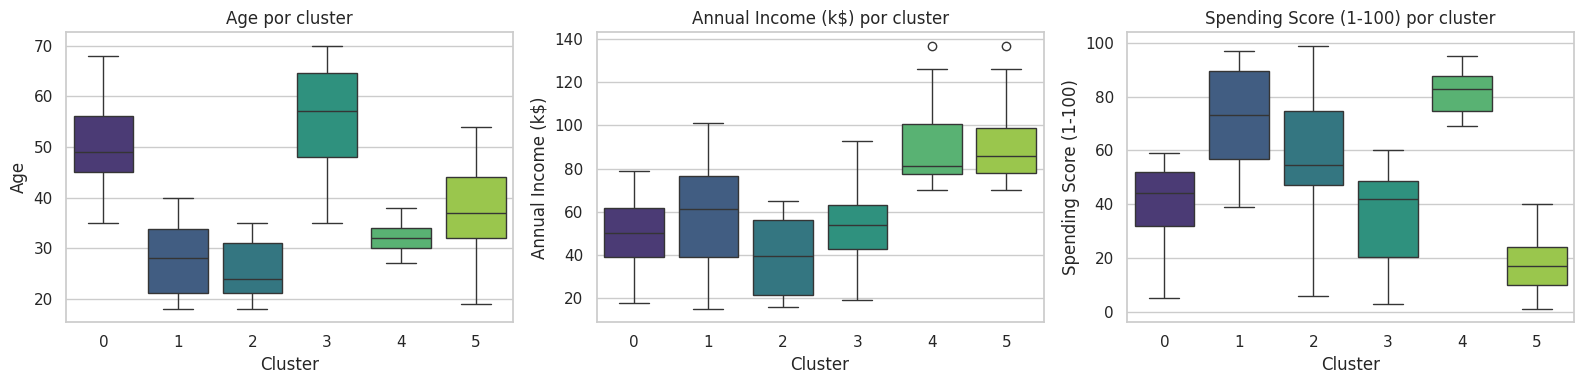

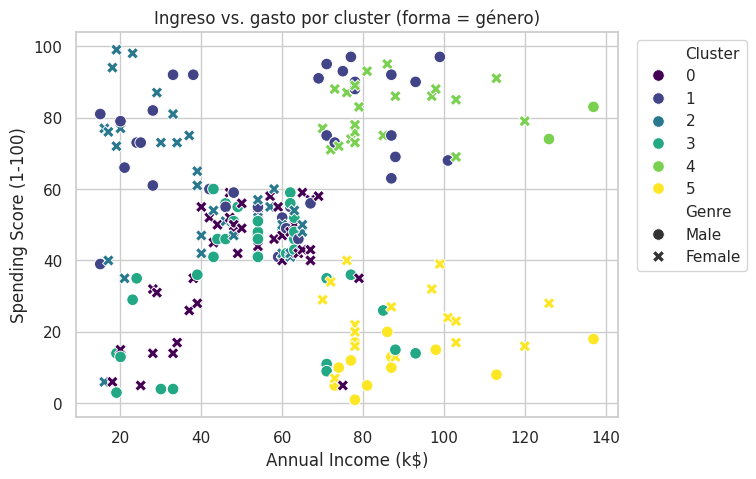

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(data=df, x="Cluster", y=col, ax=ax, palette="viridis")
    ax.set_title(f"{col} por cluster")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", style="Genre", palette="viridis", s=70)
plt.title("Ingreso vs. gasto por cluster (forma = género)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

### 9.4 Perfil de cada cluster (K-Means, k = 6)

| Cluster | n | Género | Edad prom. (rango) | Ingreso prom. k$ (rango) | Spending prom. (rango) | Interpretación / "persona" |
|---:|---:|---|---:|---:|---:|---|
| 0 | 41 | 100% mujeres | 50.6 (35–68) | 49.7 (18–79) | 40.1 (5–59) | **Mujeres maduras de ingreso medio y gasto moderado-bajo:** clientas estables y conservadoras. |
| 1 | 38 | 100% hombres | 28.1 (18–40) | 58.3 (15–101) | 71.3 (39–97) | **Hombres jóvenes de gasto alto:** el ingreso varía mucho (el boxplot más amplio), lo que los une es la edad y la disposición a gastar. Incluye a los hombres jóvenes de ingreso alto y gasto alto. |
| 2 | 34 | 100% mujeres | 26.0 (18–35) | 39.5 (16–65) | 59.5 (6–99) | **Mujeres jóvenes de ingreso bajo-medio y gasto medio-alto en promedio**, pero el gasto es muy **heterogéneo** (de 6 a 99, el rango más amplio de todos): lo que las une es la edad y el ingreso, no el gasto. |
| 3 | 35 | 100% hombres | 55.6 (35–70) | 52.8 (19–93) | 36.2 (3–60) | **Hombres maduros de ingreso medio y gasto bajo-moderado:** el segmento menos activo en compras. |
| 4 | 23 | 91% mujeres | 32.1 (27–38) | 90.0 (70–137) | 81.4 (69–95) | **Clientes premium:** adultos jóvenes con ingreso alto y gasto alto. Es el segmento más rentable. |
| 5 | 29 | 55% mujeres / 45% hombres | 36.5 (19–54) | 89.5 (70–137) | 18.0 (1–40) | **Ingreso alto, gasto bajo:** tienen poder adquisitivo pero no lo gastan en el centro comercial. |

**Observaciones:**
- En los segmentos de ingreso medio (0 a 3) el **género** y la **edad** definen los grupos. En los de ingreso alto (4 y 5) lo que los distingue es el **gasto**: ambos tienen el mismo rango de ingreso (70–137k), pero sus rangos de gasto no se solapan (69–95 vs. 1–40).
- Como se anticipó en la Fase 1, el cluster premium quedó casi solo con mujeres: los hombres jóvenes de ingreso y gasto altos están en el cluster 1. Una campaña "premium" debería incluir también a esa parte del cluster 1.

### Pregunta — ¿Algún cluster sorprendente?

Sí, el **cluster 5: ingreso alto (≈ 90k en promedio, todos por encima de 70k) con gasto muy bajo (≈ 18, ninguno por encima de 40)**. Son clientes con capacidad de compra que el centro comercial no está aprovechando, probablemente porque compran en otro lugar (online o en tiendas especializadas) o vienen solo por necesidades puntuales. La estrategia sería de **captación y activación**: averiguar qué buscan (encuestas, análisis de visitas), atraer marcas premium, ofrecer experiencias exclusivas (eventos privados, personal shopper) y dar incentivos de primera compra en categorías de alto valor. Si una parte de este grupo empezara a comportarse como el cluster 4, el impacto en ventas sería alto.

También llama la atención el **cluster 2**: mujeres jóvenes de ingreso relativamente bajo cuyo gasto promedio es medio-alto, aunque muy disperso (hay clientas que casi no gastan y otras que están entre las que más gastan). Es un grupo sensible al precio, en el que funcionan bien las promociones, los programas de puntos y el pago a cuotas. Por la dispersión del gasto, podría convenir subdividirlo para las campañas.

## Fase 8 — El cluster como variable objetivo

In [ ]:
X = df[["Genre_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]]
y = df["Cluster"]
y.value_counts().sort_index()

,count
Cluster,
0,41
1,38
2,34
3,35
4,23
5,29


## Fase 9 — Clasificador: KNN
### 11.1 División train/test

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Clientes por cluster en test:", y_test.value_counts().sort_index().to_dict())

Train: (160, 4) | Test: (40, 4)
Clientes por cluster en test: {0: 8, 1: 8, 2: 7, 3: 7, 4: 4, 5: 6}


**¿Por qué `stratify=y`?** Los clusters tienen tamaños distintos (de 23 a 41 clientes) y el test solo tiene 40 filas. Sin estratificar, un cluster pequeño como el 4 podría quedar con muy pocos ejemplos en train o en test. `stratify` mantiene en ambos conjuntos la misma proporción de cada cluster que en el dataset completo, así la evaluación es representativa y el modelo ve ejemplos de todos los segmentos.

### 11.2 Entrenamiento

Usamos **KNN** dentro de un `Pipeline` con `StandardScaler`, porque KNN se basa en distancias. Para elegir `n_neighbors` usamos **validación cruzada de 5 folds solo sobre el conjunto de entrenamiento**, así el test queda reservado para la evaluación final.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    p = Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    s = cross_val_score(p, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"n_neighbors": k, "accuracy CV (media)": s.mean(), "desv. estándar": s.std()})
cv_table = pd.DataFrame(rows).set_index("n_neighbors")
cv_table.round(4)

,accuracy CV (media),desv. estándar
n_neighbors,,
1,0.9688,0.0198
3,0.9375,0.0395
5,0.9375,0.0395
7,0.9438,0.0459
9,0.9562,0.0319
11,0.9438,0.0364
15,0.9250,0.0424


**Elección de `n_neighbors`:** `n_neighbors = 1` obtiene la mayor accuracy en validación cruzada (0.969), pero con un solo vecino el modelo copia la etiqueta del punto de entrenamiento más cercano, así que es muy sensible a clientes atípicos o mal agrupados. Por eso lo descartamos y elegimos el mejor valor entre los demás: **`n_neighbors = 9`** (0.956). La diferencia con k = 1 (≈ 0.013) es menor que la variación entre folds (desviación ≈ 0.02–0.03), es decir, no es significativa.

In [ ]:
best_k = cv_table.drop(index=1)["accuracy CV (media)"].idxmax()
print("n_neighbors elegido:", best_k)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=best_k))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

n_neighbors elegido: 9


## Fase 10 — Evaluación del clasificador

Accuracy: 0.975
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       0.89      1.00      0.94         8
           2       1.00      1.00      1.00         7
           3       1.00      0.86      0.92         7
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         6

    accuracy                           0.97        40
   macro avg       0.98      0.98      0.98        40
weighted avg       0.98      0.97      0.97        40

[[8 0 0 0 0 0]
 [0 8 0 0 0 0]
 [0 0 7 0 0 0]
 [0 1 0 6 0 0]
 [0 0 0 0 4 0]
 [0 0 0 0 0 6]]


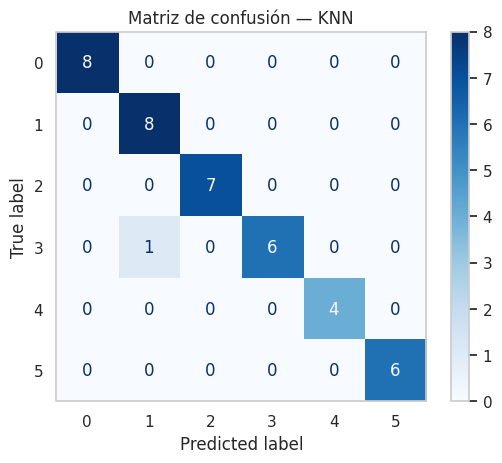

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — KNN"); plt.grid(False); plt.show()

**Análisis de errores:** revisamos los clientes concretos mal clasificados y cómo votaron sus vecinos más cercanos.

In [ ]:
errores = X_test[y_test != y_pred].assign(real=y_test[y_test != y_pred], predicho=y_pred[y_test != y_pred])
display(errores)

scaler_fit, knn_fit = pipeline.named_steps["scaler"], pipeline.named_steps["clf"]
vecinos = knn_fit.kneighbors(scaler_fit.transform(errores[X.columns]), return_distance=False)
for cliente, idx in zip(errores.index, vecinos):
    print(f"Cliente {cliente}: votos de sus {best_k} vecinos ->", y_train.iloc[idx].value_counts().to_dict())

,Genre_encoded,Age,Annual Income (k$),Spending Score (1-100),real,predicho
20,1,35,24,35,3,1


Cliente 20: votos de sus 9 vecinos -> {1: 5, 3: 4}


### Preguntas de cierre

**1. ¿Qué tan bien predice el clasificador?** Muy bien: **accuracy = 97.5% en test** (39 de 40 clientes) y ≈ 95.6% en validación cruzada sobre train. Los dos valores son consistentes, así que el resultado no depende de una partición afortunada.

**2. ¿Qué dice un accuracy cercano a 1.0?** Que los clusters son **muy separables en el espacio de características original**. Es en parte esperable: las etiquetas las generó K-Means con estas mismas 4 variables (estandarizadas), de modo que cada cluster es una región bien delimitada de ese espacio (K-Means asigna cada punto al centroide más cercano, y eso produce fronteras nítidas aunque los grupos estén pegados) y un modelo basado en distancias como KNN la reproduce casi siempre. Un accuracy alto **confirma que el clasificador aprendió la regla de segmentación**, pero no prueba por sí solo que los segmentos sean útiles para el negocio; eso lo valida el perfilado de la Fase 7.

**3. ¿Dónde se equivoca?** Hubo un único error, y la tabla de arriba muestra el cliente concreto: un **hombre de 35 años, ingreso 24k y gasto 35**, que pertenece al **cluster 3** (hombres maduros) y fue clasificado como **1** (hombres jóvenes). Tiene sentido que el modelo dude con él:
- Ambos clusters son **100% hombres**, así que el género no ayuda a separarlos.
- Su **edad (35) es justo la mínima del cluster 3** (35–70) y está dentro del rango del cluster 1 (18–40): es un cliente de frontera.
- Su gasto (35) encaja mejor con el cluster 3, pero está muy cerca del mínimo del cluster 1 (39).
- La votación de sus 9 vecinos fue **5 a 4** a favor del cluster 1: el error se decidió por un solo vecino.

En el perfilado, los clusters 1 y 3 se diferencian sobre todo por edad y gasto, y este cliente está en el límite de ambas variables. Es un error razonable.

**Uso práctico:** asignar el segmento a clientes nuevos sin volver a ejecutar el clustering.

In [ ]:
nuevos = pd.DataFrame({
    "Genre_encoded": [0, 1, 0],
    "Age": [29, 45, 60],
    "Annual Income (k$)": [95, 90, 45],
    "Spending Score (1-100)": [85, 15, 40],
})
nuevos.assign(Segmento_predicho=pipeline.predict(nuevos))

,Genre_encoded,Age,Annual Income (k$),Spending Score (1-100),Segmento_predicho
0,0,29,95,85,4
1,1,45,90,15,5
2,0,60,45,40,0


Los tres clientes de ejemplo reciben segmentos coherentes con sus perfiles: una mujer de 29 años con ingreso 95k y gasto 85 cae en el **cluster 4 (premium)**, un hombre de 45 con ingreso 90k y gasto 15 en el **cluster 5 (ingreso alto, gasto bajo)**, y una mujer de 60 con ingreso 45k y gasto 40 en el **cluster 0 (mujeres maduras de gasto moderado)**. Esta es la utilidad del clasificador: segmentar a un cliente nuevo al instante, sin volver a ejecutar el clustering sobre todo el dataset.

## Reflexión final

**¿El método con mayor Silhouette fue el que usamos?**
Entre las tres configuraciones finales de la Fase 5, sí: K-Means con k = 6 tiene el mayor Silhouette (0.331) y es el que usamos. Pero no elegimos la configuración con el Silhouette más alto de toda la exploración: K-Means con k = 8 (0.388) solo divide los mismos comportamientos por género, y DBSCAN con eps = 0.5 (0.475) deja un cuarto de los clientes como ruido en 18 micro-grupos. Priorizamos segmentos interpretables, accionables y que cubran a todos los clientes, como se discutió con Iris.

**Recomendación de marketing por segmento:**
- **Cluster 0 — Mujeres maduras, ingreso medio, gasto moderado:** fidelizar con un programa de beneficios estable y descuentos en hogar, salud y bienestar.
- **Cluster 1 — Hombres jóvenes de gasto alto:** campañas digitales y en redes con lanzamientos de tecnología, deporte y moda, y una línea premium para quienes tienen ingreso alto.
- **Cluster 2 — Mujeres jóvenes, ingreso bajo-medio, gasto variado (medio-alto en promedio):** promociones, puntos acumulables y pago a cuotas en moda y belleza.
- **Cluster 3 — Hombres maduros, gasto bajo-moderado:** ofertas prácticas y de conveniencia (servicios, restaurantes, hogar) para aumentar sus visitas y el ticket promedio.
- **Cluster 4 — Premium (ingreso alto, gasto alto):** programa VIP con atención personalizada, preventas exclusivas y marcas premium para retenerlos.
- **Cluster 5 — Ingreso alto, gasto bajo:** campañas de activación con marcas de alta gama, experiencias exclusivas e incentivos de primera compra.